# NumPy だけで MLP の順伝播・逆伝播を書く

**出典**　機械学習 4 分野の教科書 — 第 6 章 2-A 基礎と学習の安定化 ／ 03 順伝播と逆伝播

**このノートのパス**　`ml-code/06_nn_basics/02_mlp_backprop_numpy.ipynb`

**このノートで確かめること**
本文の式 `z = W a + b`、`δ³ = ŷ − y`、`δˡ = (Wˡ⁺¹)ᵀ δˡ⁺¹ ⊙ φ′(zˡ)`、`∂L/∂W = δ aᵀ` を、
**フレームワークを使わずに NumPy だけで**実装する。

1. 逆伝播で求めた勾配が、数値微分と一致するか（勾配チェック）
2. PyTorch の `loss.backward()` と一致するか
3. 活性化関数を外すと、同じ層数でも曲がった境界が引けなくなるか（02 節の主張）

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `numpy`, `scikit-learn`, `matplotlib`（② だけ `torch`） |
| 実行時間の目安 | 約 10 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [1]:
# 未導入なら実行する（Colab など）
# !pip install -q numpy scikit-learn matplotlib torch

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# 三日月型の 2 クラスデータ：直線では分けられない
X, y = make_moons(n_samples=600, noise=0.2, random_state=0)
rng = np.random.default_rng(0)
idx = rng.permutation(len(X))
tr, te = idx[:400], idx[400:]
X_tr, y_tr, X_te, y_te = X[tr], y[tr], X[te], y[te]
print("train:", X_tr.shape, " test:", X_te.shape, " classes:", np.bincount(y_tr))

train: (400, 2)  test: (200, 2)  classes: [193 207]


## ① 順伝播と逆伝播を書く

本文と同じく、層 `l` の重みは（この層のユニット数）×（前の層のユニット数）の行列 `W` とする。
ミニバッチは行方向に並べるので、`z = W a + b` は `Z = A Wᵀ + b` と書く。

In [3]:
def init_params(sizes, rng):
    """He 初期化：W ~ N(0, 2 / n_in)"""
    return [[rng.normal(0, np.sqrt(2 / n_in), size=(n_out, n_in)), np.zeros(n_out)]
            for n_in, n_out in zip(sizes[:-1], sizes[1:])]

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)          # 桁あふれ防止
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def forward(params, X, act="relu"):
    """順伝播。逆伝播に使う中間値 (z, a) をすべて保存して返す"""
    a, cache = X, [(None, X)]
    for l, (W, b) in enumerate(params):
        z = a @ W.T + b                          # z = W a + b
        last = l == len(params) - 1
        a = softmax(z) if last else (np.maximum(z, 0) if act == "relu" else z)
        cache.append((z, a))
    return a, cache

def loss_fn(P, y):
    """交差エントロピーの平均"""
    return -np.log(P[np.arange(len(y)), y] + 1e-12).mean()

def backward(params, cache, y, act="relu"):
    """逆伝播。各層の (∂L/∂W, ∂L/∂b) を返す"""
    N = len(y)
    P = cache[-1][1]
    Y = np.eye(P.shape[1])[y]
    delta = (P - Y) / N                          # δ = ŷ − y（平均損失なので 1/N）
    grads = [None] * len(params)
    for l in range(len(params) - 1, -1, -1):
        a_prev = cache[l][1]
        grads[l] = [delta.T @ a_prev, delta.sum(axis=0)]   # ∂L/∂W = δ aᵀ, ∂L/∂b = δ
        if l > 0:
            z_prev = cache[l][0]
            dphi = (z_prev > 0).astype(float) if act == "relu" else np.ones_like(z_prev)
            delta = (delta @ params[l][0]) * dphi          # δ = Wᵀ δ ⊙ φ′(z)
    return grads

sizes = [2, 16, 16, 2]                           # 入力 2 → 隠れ 16 → 隠れ 16 → 出力 2
params = init_params(sizes, np.random.default_rng(1))
P, cache = forward(params, X_tr)
print("パラメータ数:", sum(W.size + b.size for W, b in params))
print("中間値の形:", [a.shape for _, a in cache])
print(f"初期損失: {loss_fn(P, y_tr):.4f}  （参考：五分五分の予測なら ln2 = {np.log(2):.4f}）")

パラメータ数: 354
中間値の形: [(400, 2), (400, 16), (400, 16), (400, 2)]
初期損失: 1.1237  （参考：五分五分の予測なら ln2 = 0.6931）


## ② 勾配チェック：逆伝播は正しいか

逆伝播の勾配を、**全パラメータについて**中心差分の数値微分と比べる。
数値微分は「重みの数 × 2 回」順伝播をやり直す必要がある——本文の「100 万パラメータなら 100 万回」の遅さを小さく体験する。
さらに、同じ重みを PyTorch に渡して `loss.backward()` の結果とも比べる。

In [4]:
import time

def numerical_grads(params, X, y, eps=1e-6):
    num = []
    for W, b in params:
        gs = []
        for arr in (W, b):
            g = np.zeros_like(arr)
            for i in np.ndindex(arr.shape):
                old = arr[i]
                arr[i] = old + eps; lp = loss_fn(forward(params, X)[0], y)
                arr[i] = old - eps; lm = loss_fn(forward(params, X)[0], y)
                arr[i] = old
                g[i] = (lp - lm) / (2 * eps)
            gs.append(g)
        num.append(gs)
    return num

t0 = time.perf_counter()
bp = backward(params, forward(params, X_tr)[1], y_tr)
t_bp = time.perf_counter() - t0

t0 = time.perf_counter()
nd = numerical_grads(params, X_tr, y_tr)
t_nd = time.perf_counter() - t0

flat = lambda gs: np.concatenate([g.ravel() for pair in gs for g in pair])
g_bp, g_nd = flat(bp), flat(nd)
rel = np.linalg.norm(g_bp - g_nd) / np.linalg.norm(g_bp + g_nd)
print(f"逆伝播 vs 数値微分  相対誤差: {rel:.2e}  ← 1e-7 未満なら一致")
print(f"計算時間  逆伝播: {t_bp*1e3:.2f} ms   数値微分: {t_nd*1e3:.0f} ms"
      f"（順伝播 {2*g_bp.size} 回）")

逆伝播 vs 数値微分  相対誤差: 2.75e-10  ← 1e-7 未満なら一致
計算時間  逆伝播: 0.58 ms   数値微分: 35 ms（順伝播 708 回）


In [5]:
import torch

tp = [[torch.tensor(W, requires_grad=True), torch.tensor(b, requires_grad=True)] for W, b in params]
h = torch.tensor(X_tr)
for l, (W, b) in enumerate(tp):
    h = h @ W.T + b
    if l < len(tp) - 1:
        h = torch.relu(h)
loss = torch.nn.functional.cross_entropy(h, torch.tensor(y_tr))
loss.backward()                                  # 自動微分

g_torch = np.concatenate([t.grad.numpy().ravel() for pair in tp for t in pair])
print(f"損失  NumPy: {loss_fn(forward(params, X_tr)[0], y_tr):.10f}   PyTorch: {loss.item():.10f}")
print(f"逆伝播 vs loss.backward()  最大絶対差: {np.abs(g_bp - g_torch).max():.2e}")

損失  NumPy: 1.1237279439   PyTorch: 1.1237279439
逆伝播 vs loss.backward()  最大絶対差: 4.44e-16


## ③ 学習させる：活性化関数あり vs なし

同じ `[2, 16, 16, 2]` の構造で、隠れ層を ReLU にしたものと、恒等関数（活性化なし）にしたものを
ミニバッチ SGD で同じ条件で学習させる。

In [6]:
def train(act, epochs=300, lr=0.3, batch=32, seed=1):
    rng = np.random.default_rng(seed)
    params = init_params(sizes, rng)
    hist = []
    for ep in range(epochs):
        for s in np.array_split(rng.permutation(len(X_tr)), len(X_tr) // batch):
            _, cache = forward(params, X_tr[s], act)
            for (W, b), (gW, gb) in zip(params, backward(params, cache, y_tr[s], act)):
                W -= lr * gW                     # θ ← θ − η ∇L
                b -= lr * gb
        hist.append(loss_fn(forward(params, X_tr, act)[0], y_tr))
    return params, hist

acc = lambda p, X, y, act: (forward(p, X, act)[0].argmax(1) == y).mean()
results = {}
for act in ["linear", "relu"]:
    p, hist = train(act)
    results[act] = (p, hist)
    print(f"{act:>6}: train loss={hist[-1]:.4f}  train acc={acc(p, X_tr, y_tr, act):.3f}"
          f"  test acc={acc(p, X_te, y_te, act):.3f}")

linear: train loss=0.2563  train acc=0.895  test acc=0.865


  relu: train loss=0.0433  train acc=0.988  test acc=0.955


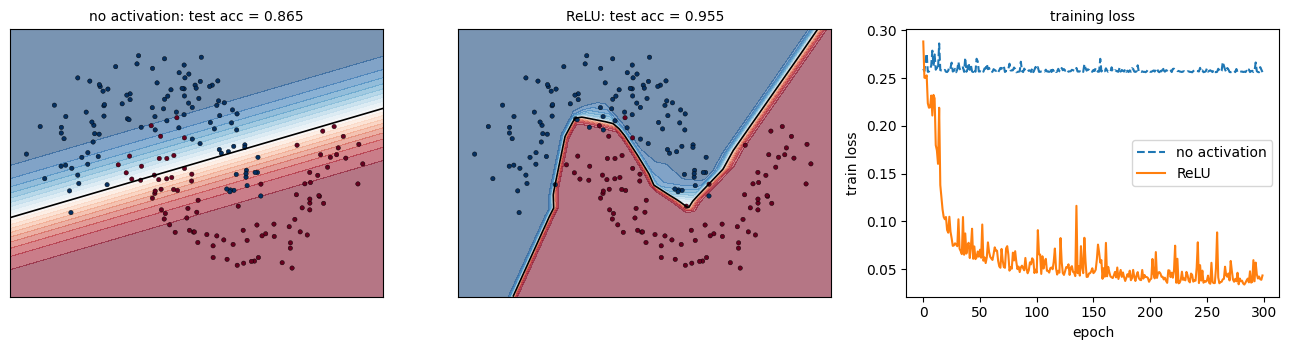

In [7]:
xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 300), np.linspace(-1.1, 1.6, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, act in zip(axes[:2], ["linear", "relu"]):
    p, _ = results[act]
    zz = forward(p, grid, act)[0][:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=0.55)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=1.2)
    ax.scatter(X_te[:, 0], X_te[:, 1], c=y_te, cmap="RdBu_r", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(f"{'no activation' if act == 'linear' else 'ReLU'}: "
                 f"test acc = {acc(p, X_te, y_te, act):.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
for act, style in [("linear", "--"), ("relu", "-")]:
    axes[2].plot(results[act][1], style, label="no activation" if act == "linear" else "ReLU")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("train loss"); axes[2].legend()
axes[2].set_title("training loss", fontsize=10)
plt.tight_layout(); plt.show()

## 読み取りどころ

- **勾配チェックは「逆伝播を自作したら必ずやる」儀式。**相対誤差が 1e-7 前後を超えたら、どこかの `δ` か転置を間違えている。
- **数値微分は正しいが遅い。**わずか 354 パラメータでも逆伝播の数十倍の時間がかかり、その差はパラメータ数に比例して開く。逆伝播が「順伝播 1 回＋逆向き 1 回」で済むことの価値はここにある。
- **PyTorch の `loss.backward()` は、上の `backward()` と同じ計算をしている。**結果は浮動小数点誤差の範囲で一致する。
- **活性化関数を外すと、16 ユニット × 2 層あっても境界は直線のまま**。これは 02 節の `W₃W₂W₁ = W′` を、学習結果として確かめたことになる。